# Cierre experimental: Soft MoE con Feature Engineering

Este notebook recupera el **Soft Mixture of Experts (Soft MoE) con Feature Engineering** seleccionado en el notebook de modelado. Primero comprueba sus resultados sobre la validación reservada para la selección; después reentrena la misma arquitectura con todo el histórico etiquetado (entrenamiento y validación), genera predicciones sobre test y analiza la corrección residual mediante SHAP.

La predicción combina de forma continua la referencia anual `Lag_52` con una corrección aprendida. **No se utiliza el umbral del hard gating**: aquel fue una alternativa experimental, no una regla de decisión del modelo definitivo.

La validación intervino en la selección del modelo y de su duración de entrenamiento. Por tanto, sus métricas no constituyen una evaluación independiente. El test de Kaggle carece de `Weekly_Sales`, por lo que no es posible calcular métricas de rendimiento sobre test.

## 1. Configuración y carga de datos

`TRAIN=False` reutiliza el modelo definitivo si existen artefactos compatibles; en la primera ejecución, cuando aún no existen, lo entrena y guarda automáticamente. `TRAIN=True` fuerza el reentrenamiento definitivo. En ambos casos se recuperan los pesos del **Soft MoE + FE de selección** para verificar sus predicciones; este modelo no se vuelve a entrenar aquí. `RUN_SHAP` permite recuperar o generar el análisis interpretativo; `TRAIN=False` reutiliza artefactos existentes y calcula únicamente los que falten o sean incompatibles. Las salidas descriptivas se conservan cuando ya existen. `TRAIN=True` fuerza el reentrenamiento y la actualización de los artefactos dependientes.

In [1]:
TRAIN = False
SEED = 42
RUN_SHAP = True
# TRAIN=False: reutilizar resultados compatibles; completar solo lo que falte.
# TRAIN=True: forzar reentrenamiento y actualización de resultados dependientes.
SHAP_BACKGROUND = 32
SHAP_SAMPLES = 128
SHAP_PERMUTATIONS = 10

In [2]:
import importlib.util, subprocess, sys
if RUN_SHAP and importlib.util.find_spec('shap') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shap'])
from pathlib import Path
import json, hashlib, platform, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown
from google.colab import drive

drive.mount('/content/drive')
tf.keras.utils.set_random_seed(SEED)
ROOT = Path('/content/drive/MyDrive/TFM')
NN_DATA = ROOT/'data/neural_networks'
EXPORT_DATA = ROOT/'data/final_model'
SOURCE_MODEL = ROOT/'models/soft_moe_feature_engineering_v1'
OUTPUT = ROOT/'results/final_soft_moe_fe'
FINAL_MODEL = ROOT/'models/final_soft_moe_fe_full_history'
for directory in [OUTPUT, FINAL_MODEL, OUTPUT/'shap']:
    directory.mkdir(parents=True, exist_ok=True)
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'tensorflow': tf.__version__}
print('Versiones:', VERSIONS)

Mounted at /content/drive
Versiones: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'tensorflow': '2.21.0'}


In [3]:
KEYS = ['Store', 'Dept', 'Date']
TARGET, RESIDUAL_TARGET, BASELINE = 'Weekly_Sales', 'Residual_52', 'Lag_52'
required = [NN_DATA/n for n in ['train_internal_nn.parquet','validation_nn.parquet','test_nn.parquet']]
required += [EXPORT_DATA/n for n in ['train_final.parquet','validation_final.parquet',
                                     'test_final.parquet','feature_config.json']]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError('Faltan exportaciones de los notebooks anteriores: '+str(missing))
train_raw, val_raw, test_raw = [pd.read_parquet(p) for p in required[:3]]
export_train, export_val, export_test = [pd.read_parquet(p) for p in required[3:6]]
feature_config = json.loads(required[6].read_text())
for df in [train_raw,val_raw,test_raw,export_train,export_val,export_test]:
    df['Date'] = pd.to_datetime(df['Date'])
    assert not df.duplicated(KEYS).any(), 'Claves duplicadas'
assert train_raw['Date'].max() < val_raw['Date'].min() < test_raw['Date'].min()
assert TARGET not in test_raw and TARGET not in export_test
assert RESIDUAL_TARGET not in test_raw and RESIDUAL_TARGET not in export_test
print('Filas originales:', len(train_raw),len(val_raw),len(test_raw))

Filas originales: 305982 115588 115064


### 1.1. Variables y configuración seleccionada

Se conservan las 38 variables originales del experimento con Feature Engineering. El preprocesamiento genera más columnas tras la codificación categórica *one-hot*. La puerta neuronal y el experto residual reciben estas mismas entradas; el segundo experto corresponde al residuo cero, que equivale a mantener `Lag_52`.

In [4]:
CAT = ['Store','Dept','Type','HolidayType']
NUM = ['Lag_51','Lag_52','Lag_53','Lag_Local_Mean','Lag_Local_Trend',
       'Lag_52_Deviation','Lag_Local_Std','Lag_Available_Count','Lag_Imputed_Count',
       'Temperature','Fuel_Price','Delta_Temperature','Delta_Fuel_Price',
       'MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5','Size',
       'TimeIndex','WeekSin','WeekCos']
BIN = ['IsHoliday','Lag_51_isna','Lag_52_isna','Lag_53_isna',
       'Lag_51_imputed','Lag_52_imputed','Lag_53_imputed',
       'MarkDown1_isna','MarkDown2_isna','MarkDown3_isna',
       'MarkDown4_isna','MarkDown5_isna']
FEATURES = CAT+NUM+BIN
assert len(FEATURES)==38 and len(set(FEATURES))==38
for key, expected in [('categorical_features',CAT),('numeric_features',NUM),
                      ('binary_features',BIN),('model_features',FEATURES)]:
    assert feature_config[key] == expected, f'Configuración incompatible: {key}'
assert feature_config['target']==TARGET
assert feature_config['residual_target']==RESIDUAL_TARGET
assert feature_config['baseline_feature']==BASELINE
CONFIG = {'architecture':'soft_moe_feature_engineering','features':FEATURES,
          'categorical':CAT,'numeric':NUM,'binary':BIN,'baseline':BASELINE,
          'target':RESIDUAL_TARGET,'expert_hidden':[128,64],
          'expert_dropout':[.20,.10],'gate_hidden':[32,16],
          'optimizer':'Adam','learning_rate':.001,'loss':'mae',
          'holiday_weight':5.0,'batch_size':256,'seed':SEED,
          'max_gap':5,'holiday_gap_exclusion':True,'lags':[51,52,53]}
(OUTPUT/'selected_config.json').write_text(json.dumps(CONFIG,indent=2))
print('Modelo seleccionado: Soft MoE + FE; variables:',len(FEATURES))

Modelo seleccionado: Soft MoE + FE; variables: 38


### 1.2. Reconstrucción temporal de las variables

Los conjuntos finales exportados contienen únicamente filas cubiertas; para reconstruir los retardos es necesario conservar el histórico completo. Se aplican las reglas del notebook anterior: interpolación de huecos internos de hasta cinco semanas, exclusión de huecos que contienen festividades ausentes y búsqueda de retardos por fecha exacta. Las ventas objetivo no se interpolan. Se comprueba que las fuentes de información son anteriores al objetivo y, para validación y test, anteriores al origen de predicción.

In [5]:
holiday_dates = {

    # -------------------------------------------------------------------------
    # SUPER BOWL
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-02-12"):
        "SuperBowl",

    pd.Timestamp("2011-02-11"):
        "SuperBowl",

    pd.Timestamp("2012-02-10"):
        "SuperBowl",

    pd.Timestamp("2013-02-08"):
        "SuperBowl",


    # -------------------------------------------------------------------------
    # LABOR DAY
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-09-10"):
        "LaborDay",

    pd.Timestamp("2011-09-09"):
        "LaborDay",

    pd.Timestamp("2012-09-07"):
        "LaborDay",


    # -------------------------------------------------------------------------
    # THANKSGIVING
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-11-26"):
        "Thanksgiving",

    pd.Timestamp("2011-11-25"):
        "Thanksgiving",

    pd.Timestamp("2012-11-23"):
        "Thanksgiving",


    # -------------------------------------------------------------------------
    # CHRISTMAS
    # -------------------------------------------------------------------------
    pd.Timestamp("2010-12-31"):
        "Christmas",

    pd.Timestamp("2011-12-30"):
        "Christmas",

    pd.Timestamp("2012-12-28"):
        "Christmas"
}

HOLIDAY_CATEGORIES = [
    "None",
    "SuperBowl",
    "LaborDay",
    "Thanksgiving",
    "Christmas"
]

def add_holiday_type(df):

    df = df.copy()

    df["HolidayType"] = (
        df["Date"]
        .map(
            holiday_dates
        )
        .fillna(
            "None"
        )
    )


    df["HolidayType"] = pd.Categorical(
        df["HolidayType"],
        categories=HOLIDAY_CATEGORIES
    )


    return df

In [6]:
def build_interpolated_sales_history(df,max_gap=5,holiday_dates=None):

    # -------------------------------------------------------------------------
    # Histórico original
    # -------------------------------------------------------------------------

    base = (
        df[["Store","Dept","Date","Weekly_Sales"]]
        .copy()
        .sort_values(["Store","Dept","Date"])
        .reset_index(drop=True)
    )

    base["Date"] = pd.to_datetime(base["Date"])


    # -------------------------------------------------------------------------
    # Comprobación de unicidad
    # -------------------------------------------------------------------------

    duplicates = base.duplicated(subset=["Store","Dept","Date"]).sum()

    if duplicates > 0:
        raise ValueError(f"Existen {duplicates} duplicados Store-Dept-Date.")

    # -------------------------------------------------------------------------
    # Fechas festivas
    # -------------------------------------------------------------------------

    if holiday_dates is None:
        holiday_set = set()
    else:
        holiday_set = set(
            pd.Timestamp(date) for date in holiday_dates.keys())


    # -------------------------------------------------------------------------
    # Contadores para auditoría
    # -------------------------------------------------------------------------

    candidate_gaps = 0
    candidate_weeks = 0

    interpolated_gaps = 0
    interpolated_weeks = 0

    skipped_holiday_gaps = 0
    skipped_holiday_weeks = 0

    synthetic_rows = []


    # -------------------------------------------------------------------------
    # Procesamiento por serie Store-Dept
    # -------------------------------------------------------------------------

    for (store, dept), group in base.groupby(["Store","Dept"],sort=False):

        group = (group.sort_values("Date").reset_index(drop=True))
        dates = group["Date"].to_numpy()
        sales = group["Weekly_Sales"].to_numpy()
        # ---------------------------------------------------------------------
        # Comparación entre observaciones consecutivas reales
        # ---------------------------------------------------------------------

        for i in range(len(group) - 1):
            left_date = pd.Timestamp(dates[i])
            right_date = pd.Timestamp(dates[i + 1])
            days_between = (right_date-left_date).days
            # -------------------------------------------------------------
            # La frecuencia esperada es semanal.
            # -------------------------------------------------------------
            if days_between <= 7:
                continue
            # Si no es múltiplo de 7 no consideramos el intervalo
            # una secuencia semanal estándar.
            if days_between % 7 != 0:
                continue

            weeks_between = days_between // 7

            missing_weeks = weeks_between - 1
            # -------------------------------------------------------------
            # Solo huecos internos entre 1 y max_gap
            # -------------------------------------------------------------

            if not (1<= missing_weeks<= max_gap):
                continue

            candidate_gaps += 1
            candidate_weeks += missing_weeks


            # -------------------------------------------------------------
            # Fechas ausentes
            # -------------------------------------------------------------

            missing_dates = [left_date+ pd.Timedelta(weeks=j)
                for j in range(1,missing_weeks + 1)]


            # -------------------------------------------------------------
            # Criterio conservador:
            #
            # si alguna semana ausente es festiva,
            # no reconstruimos el hueco completo.
            # -------------------------------------------------------------

            contains_holiday = any(
                date in holiday_set for date in missing_dates)

            if contains_holiday:

                skipped_holiday_gaps += 1
                skipped_holiday_weeks += missing_weeks

                continue


            # -------------------------------------------------------------
            # Valores de los dos extremos observados
            # -------------------------------------------------------------

            y_left = float(sales[i])
            y_right = float(sales[i + 1])

            # -------------------------------------------------------------
            # Interpolación lineal
            # -------------------------------------------------------------

            for j, missing_date in enumerate(missing_dates,start=1):

                weight = (j/(missing_weeks + 1))
                y_interp = y_left + weight * (y_right - y_left)
                synthetic_rows.append({
                    "Store":store,
                    "Dept":dept,
                    "Date":missing_date,
                    "Weekly_Sales_History":y_interp,
                    "Sales_Imputed":True,
                    "Imputation_Gap_Size":missing_weeks,
                    "Imputation_Position":j,
                    "Source_Left_Date":left_date,
                    "Source_Right_Date":right_date
                })

            interpolated_gaps += 1
            interpolated_weeks += missing_weeks

    # =========================================================================
    # OBSERVACIONES REALES
    # =========================================================================

    observed_history = (base.rename(columns={"Weekly_Sales":
                    "Weekly_Sales_History"}).copy())

    observed_history["Sales_Imputed"] = False
    observed_history["Imputation_Gap_Size"] = 0
    observed_history["Imputation_Position"] = 0
    observed_history["Source_Left_Date"] = pd.NaT
    observed_history["Source_Right_Date"] = pd.NaT

    # =========================================================================
    # OBSERVACIONES RECONSTRUIDAS
    # =========================================================================

    synthetic_history = pd.DataFrame(synthetic_rows)

    # =========================================================================
    # HISTÓRICO COMPLETO
    # =========================================================================

    if len(synthetic_history) > 0:

        history = pd.concat([observed_history,synthetic_history],
                            ignore_index=True)

    else:

        history = observed_history.copy()
    history = (history.sort_values(["Store","Dept","Date"])
    .reset_index(drop=True))

    # =========================================================================
    # ESTADÍSTICAS DEL PROCEDIMIENTO
    # =========================================================================

    stats = {
        "Original_rows":len(base),
        "Candidate_gaps":candidate_gaps,
        "Candidate_missing_weeks":candidate_weeks,
        "Interpolated_gaps":interpolated_gaps,
        "Interpolated_weeks":interpolated_weeks,
        "Skipped_holiday_gaps":skipped_holiday_gaps,
        "Skipped_holiday_weeks":skipped_holiday_weeks,
        "Final_history_rows":len(history)
    }

    return history, stats

In [7]:
def add_exact_sales_lags(target_df,history_df,lag_weeks=(51,52,53)):

    result = target_df.copy()

    # Eliminar versiones anteriores de los lags que vamos a recalcular
    lag_prefixes = tuple(f"Lag_{lag}" for lag in lag_weeks)
    cols_to_drop = [col for col in result.columns if col.startswith(lag_prefixes)]

    if cols_to_drop:
        result = result.drop(columns=cols_to_drop)

    history_lookup = history_df[
        ["Store","Dept","Date","Weekly_Sales_History",
         "Sales_Imputed","Source_Right_Date"]
    ].copy()

    # -------------------------------------------------------------------------
    # Garantía de unicidad del histórico
    # -------------------------------------------------------------------------

    duplicated_history = history_lookup.duplicated(
        subset=["Store","Dept","Date"]
    ).sum()

    if duplicated_history > 0:
        raise ValueError(
            f"Existen {duplicated_history} fechas duplicadas en el histórico."
        )

    # =========================================================================
    # GENERACIÓN DE CADA LAG
    # =========================================================================

    for lag in lag_weeks:

        lag_date_col = f"Lag_{lag}_Date"
        lag_value_col = f"Lag_{lag}"
        lag_imputed_col = f"Lag_{lag}_imputed"
        lag_right_source_col = f"Lag_{lag}_Source_Right_Date"

        # Fecha exacta que necesitamos buscar
        result[lag_date_col] = result["Date"] - pd.Timedelta(weeks=lag)

        lookup = history_lookup.rename(columns={
            "Date":lag_date_col,
            "Weekly_Sales_History":lag_value_col,
            "Sales_Imputed":lag_imputed_col,
            "Source_Right_Date":lag_right_source_col
        })

        result = result.merge(
            lookup,
            on=["Store","Dept",lag_date_col],
            how="left",
            validate="many_to_one"
        )

        result[lag_imputed_col] = (
            result[lag_imputed_col]
            .fillna(False)
            .astype(bool)
        )

        # =====================================================================
        # CONTROL DE DATA LEAKAGE
        # =====================================================================

        interpolated_mask = result[lag_imputed_col]

        if interpolated_mask.any():

            leakage_mask = (
                interpolated_mask &
                (result[lag_right_source_col] >= result["Date"])
            )

            n_leakage = leakage_mask.sum()

            if n_leakage > 0:
                raise ValueError(
                    f"Lag_{lag}: detectados {n_leakage} casos potenciales "
                    "de data leakage."
                )

    return result

def add_lag_features(df):

    df = df.copy()
    lag_cols = ["Lag_51","Lag_52","Lag_53"]
    imputed_cols = ["Lag_51_imputed","Lag_52_imputed","Lag_53_imputed"]

    # Indicadores de ausencia
    for lag in [51,52,53]:
        df[f"Lag_{lag}_isna"] = df[f"Lag_{lag}"].isna()

    # Calidad/disponibilidad del bloque temporal
    df["Lag_Available_Count"] = df[lag_cols].notna().sum(axis=1).astype("int8")
    df["Lag_Imputed_Count"] = df[imputed_cols].sum(axis=1).astype("int8")

    # Solo calculamos features locales cuando existen los 3 lags
    complete_lags = df[lag_cols].notna().all(axis=1)

    df["Lag_Local_Mean"] = np.nan
    df["Lag_Local_Trend"] = np.nan
    df["Lag_52_Deviation"] = np.nan
    df["Lag_Local_Std"] = np.nan

    df.loc[complete_lags,"Lag_Local_Mean"] = (
        df.loc[complete_lags,lag_cols].mean(axis=1)
    )

    df.loc[complete_lags,"Lag_Local_Trend"] = (
        df.loc[complete_lags,"Lag_51"] -
        df.loc[complete_lags,"Lag_53"]
    ) / 2

    df.loc[complete_lags,"Lag_52_Deviation"] = (
        df.loc[complete_lags,"Lag_52"] -
        (
            df.loc[complete_lags,"Lag_51"] +
            df.loc[complete_lags,"Lag_53"]
        ) / 2
    )

    df.loc[complete_lags,"Lag_Local_Std"] = (
        df.loc[complete_lags,lag_cols].std(axis=1,ddof=0)
    )

    float_cols = [
        "Lag_Local_Mean",
        "Lag_Local_Trend",
        "Lag_52_Deviation",
        "Lag_Local_Std"
    ]

    df[float_cols] = df[float_cols].astype("float32")

    return df

In [8]:
def enrich(base,history,forecast_origin=None):
    df = add_holiday_type(base)
    assert (df['HolidayType'].astype(str).ne('None') == df['IsHoliday']).all()
    df = add_lag_features(add_exact_sales_lags(df,history))
    for lag in [51,52,53]:
        available = df[f'Lag_{lag}'].notna()
        source = df[f'Lag_{lag}_Date'].where(~df[f'Lag_{lag}_imputed'],
                                            df[f'Lag_{lag}_Source_Right_Date'])
        assert (source[available] < df.loc[available,'Date']).all()
        if forecast_origin is not None:
            assert (source[available] < forecast_origin).all(), 'Información posterior al origen'
    if TARGET in df:
        df[RESIDUAL_TARGET] = df[TARGET] - df[BASELINE]
    return df

def compare_export(rebuilt,exported,name):
    columns = KEYS + [c for c in FEATURES if c not in KEYS]
    if TARGET in exported: columns += [TARGET,RESIDUAL_TARGET]
    a = rebuilt.loc[rebuilt[BASELINE].notna(),columns].sort_values(KEYS).reset_index(drop=True)
    b = exported[columns].sort_values(KEYS).reset_index(drop=True)
    assert len(a) == len(b), f'Cobertura diferente: {name}'
    pd.testing.assert_frame_equal(a[KEYS],b[KEYS],check_dtype=False)
    for col in columns:
        if col in KEYS: continue
        if col in CAT:
            assert a[col].astype(str).equals(b[col].astype(str)), (name,col)
        else:
            np.testing.assert_allclose(a[col].to_numpy(dtype=float),b[col].to_numpy(dtype=float),
                                       rtol=2e-6,atol=1e-4,equal_nan=True,err_msg=f'{name}: {col}')
    print('Exportación contrastada:',name,len(a))

history_train,history_train_stats = build_interpolated_sales_history(
    train_raw,max_gap=5,holiday_dates=holiday_dates)
full_raw = pd.concat([train_raw,val_raw],ignore_index=True).sort_values(KEYS).reset_index(drop=True)
assert not full_raw.duplicated(KEYS).any()
history_full,history_full_stats = build_interpolated_sales_history(
    full_raw,max_gap=5,holiday_dates=holiday_dates)
train_selection = enrich(train_raw,history_train)
val_selection = enrich(val_raw,history_train,val_raw['Date'].min())
test_rebuilt = enrich(test_raw,history_full,test_raw['Date'].min())
compare_export(train_selection,export_train,'train')
compare_export(val_selection,export_val,'validación')
compare_export(test_rebuilt,export_test,'test')

train_covered = train_selection.loc[train_selection[BASELINE].notna()].copy()
val_covered = val_selection.loc[val_selection[BASELINE].notna()].copy()
assert np.isfinite(train_covered[RESIDUAL_TARGET]).all()
assert np.isfinite(val_covered[RESIDUAL_TARGET]).all()
print('Cobertura de validación:',len(val_covered),'/',len(val_raw))

/tmp/ipykernel_707/551150651.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_707/551150651.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_707/551150651.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_707/551150651.py:60: FutureWarning

Exportación contrastada: train 150116
Exportación contrastada: validación 113330
Exportación contrastada: test 113915
Cobertura de validación: 113330 / 115588


## 2. Recuperación y evaluación del modelo seleccionado

Se cargan los pesos, el preprocesador y el escalador **guardados durante el experimento Soft MoE + FE**. La arquitectura se reconstruye con las mismas capas y el mismo valor normalizado del experto de referencia. Si falta algún artefacto se detiene la ejecución: no sería correcto sustituir silenciosamente el modelo de selección por otro recién entrenado.

La evaluación reproduce las métricas de validación de la selección sobre las observaciones cubiertas. No se presenta como rendimiento de test ni como evaluación independiente.

In [9]:
def frame_signature(df, columns):
    data = df[columns].copy()
    for c in data.select_dtypes(include='category'):
        data[c] = data[c].astype(object)
    h = hashlib.sha256(pd.util.hash_pandas_object(data,index=True).values.tobytes())
    h.update(json.dumps(columns).encode())
    return h.hexdigest()

def object_signature(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,default=str).encode()).hexdigest()

def file_hash(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):
            h.update(block)
    return h.hexdigest()

def make_preprocessor():
    return ColumnTransformer([
        ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),
                         ('scaler',StandardScaler())]),NUM),
        ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                         ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CAT),
        ('bin','passthrough',BIN)])

def make_moe(width,baseline_scaled):
    tf.keras.utils.set_random_seed(SEED)
    inp = tf.keras.Input(shape=(width,),name='features')
    expert = tf.keras.layers.Dense(128,activation='relu',name='expert_dense_1')(inp)
    expert = tf.keras.layers.Dropout(.20,name='expert_dropout_1')(expert)
    expert = tf.keras.layers.Dense(64,activation='relu',name='expert_dense_2')(expert)
    expert = tf.keras.layers.Dropout(.10,name='expert_dropout_2')(expert)
    expert = tf.keras.layers.Dense(1,name='expert_output')(expert)
    gate = tf.keras.layers.Dense(32,activation='relu',name='gate_dense_1')(inp)
    gate = tf.keras.layers.Dense(16,activation='relu',name='gate_dense_2')(gate)
    gate = tf.keras.layers.Dense(1,activation='sigmoid',name='gate')(gate)
    baseline = tf.keras.layers.Lambda(lambda x:tf.ones_like(x)*baseline_scaled,
                                      name='baseline_expert')(expert)
    baseline_weight = tf.keras.layers.Lambda(lambda x:1.-x,name='baseline_weight')(gate)
    weighted_baseline = tf.keras.layers.Multiply()([baseline_weight,baseline])
    weighted_expert = tf.keras.layers.Multiply()([gate,expert])
    output = tf.keras.layers.Add(name='mixture_output')([weighted_baseline,weighted_expert])
    model = tf.keras.Model(inp,output,name='Residual_Soft_MoE_FE')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),loss='mae')
    return model

def baseline_scaled_value(scaler):
    # La estandarización de cero se obtiene directamente de los parámetros ajustados.
    return float((-scaler.mean_[0])/scaler.scale_[0])

def weights(df):
    return np.where(df['IsHoliday'],5.,1.).astype('float32')

def check_bundle(model,preprocessor,scaler,df):
    assert list(preprocessor.feature_names_in_)==FEATURES
    X=preprocessor.transform(df[FEATURES].head(32)).astype('float32')
    assert np.isfinite(X).all() and model.input_shape[-1]==X.shape[1]
    assert scaler.n_features_in_==1
    assert model.get_layer('expert_dense_1').units==128
    assert model.get_layer('expert_dense_2').units==64
    assert model.get_layer('gate_dense_1').units==32
    assert model.get_layer('gate_dense_2').units==16

def predict_residual(model,preprocessor,scaler,df):
    if df.empty: return np.empty(0)
    X=preprocessor.transform(df[FEATURES]).astype('float32')
    assert np.isfinite(X).all()
    y=model.predict(X,batch_size=256,verbose=0)
    residual=scaler.inverse_transform(np.asarray(y).reshape(-1,1)).ravel()
    assert np.isfinite(residual).all()
    return residual

def predict_system(model,preprocessor,scaler,df):
    baseline=df[BASELINE].to_numpy(dtype=float)
    assert np.isfinite(baseline).all()
    correction=predict_residual(model,preprocessor,scaler,df)
    return baseline+correction,correction

def metrics(df,pred):
    y=df[TARGET].to_numpy(dtype=float)
    pred=np.asarray(pred,dtype=float)
    w=weights(df)
    return {'N':len(df),'MAE':mean_absolute_error(y,pred),
            'RMSE':np.sqrt(mean_squared_error(y,pred)),
            'WMAE':np.average(np.abs(y-pred),weights=w),
            'R2':r2_score(y,pred)}

def coverage(df,name):
    return {'Conjunto':name,'Total':len(df),'Con_Lag52':int(df[BASELINE].notna().sum()),
            'Cobertura':df[BASELINE].notna().mean()}


In [10]:
SOURCE_FILES = ['soft_moe_fe.weights.h5','preprocessor.joblib','target_scaler.joblib']
missing_source=[str(SOURCE_MODEL/f) for f in SOURCE_FILES if not (SOURCE_MODEL/f).exists()]
if missing_source:
    raise FileNotFoundError('Faltan artefactos del Soft MoE + FE seleccionado: '+str(missing_source))
val_preprocessor=joblib.load(SOURCE_MODEL/'preprocessor.joblib')
val_scaler=joblib.load(SOURCE_MODEL/'target_scaler.joblib')
X_val_probe=val_preprocessor.transform(val_covered[FEATURES].head(8)).astype('float32')
val_model=make_moe(X_val_probe.shape[1],baseline_scaled_value(val_scaler))
val_model.load_weights(str(SOURCE_MODEL/'soft_moe_fe.weights.h5'))
check_bundle(val_model,val_preprocessor,val_scaler,val_covered)
val_history_path=SOURCE_MODEL/'training_history.csv'
val_history=pd.read_csv(val_history_path) if val_history_path.exists() else None
if val_history is None:
    raise FileNotFoundError('Falta training_history.csv: necesario para fijar las épocas del reentrenamiento final.')
selection_signature=object_signature({'files':{f:file_hash(SOURCE_MODEL/f) for f in SOURCE_FILES},
                                      'history':file_hash(val_history_path),
                                      'train':frame_signature(train_covered,KEYS+[c for c in FEATURES if c not in KEYS]+[RESIDUAL_TARGET]),
                                      'validation':frame_signature(val_covered,KEYS+[c for c in FEATURES if c not in KEYS]+[RESIDUAL_TARGET])})
print('Soft MoE + FE seleccionado: pesos y transformadores cargados.')
print('Columnas tras preprocesamiento:',X_val_probe.shape[1])

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Soft MoE + FE seleccionado: pesos y transformadores cargados.
Columnas tras preprocesamiento: 166


In [11]:
val_prediction,val_correction=predict_system(val_model,val_preprocessor,val_scaler,val_covered)
val_results=val_covered[KEYS+[TARGET,BASELINE,'IsHoliday','Lag_52_imputed']].copy()
val_results['Prediction']=val_prediction
val_results['Correction']=val_correction

# Extraer el peso asignado al experto MLP por el Soft MoE
gate_extractor = tf.keras.Model(
    inputs=val_model.inputs,
    outputs=val_model.get_layer("gate").output
)

X_val_gate = val_preprocessor.transform(
    val_covered[FEATURES]
).astype("float32")

val_results["Gate_Weight"] = gate_extractor.predict(
    X_val_gate,
    batch_size=256,
    verbose=0
).ravel()

assert len(val_results) == len(val_covered)
assert val_results["Gate_Weight"].between(0, 1).all()


val_results['Error']=val_results[TARGET]-val_results['Prediction']
rows=[]
for label,df,pred in [('Baseline Lag_52',val_covered,val_covered[BASELINE]),
                      ('Soft MoE + FE',val_covered,val_prediction)]:
    rows.append({'Modelo':label,**metrics(df,pred)})
validation_metrics=pd.DataFrame(rows)
display(validation_metrics.round(4))
validation_metrics.to_csv(OUTPUT/'validation_metrics.csv',index=False)
val_results.to_parquet(OUTPUT/'validation_predictions.parquet',index=False)
print('Validación cubierta:',len(val_covered),'de',len(val_raw))
print('Referencia de selección: WMAE ~1691.68 en 113330 observaciones.')
if len(val_covered)==113330:
    assert np.isclose(validation_metrics.iloc[1]['WMAE'],1691.6818,atol=2.),         'Las predicciones no reproducen el resultado seleccionado; revisar artefactos y datos.'

,Modelo,N,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,113330,1826.7676,3889.2364,1831.1555,0.9695
1,Soft MoE + FE,113330,1705.4273,3583.6674,1691.6818,0.9741


Validación cubierta: 113330 de 115588
Referencia de selección: WMAE ~1691.68 en 113330 observaciones.


### 2.1. Resultados del modelo seleccionado en validación

La recuperación del modelo permite reproducir el WMAE de **1.691,68** en **113.330 observaciones** de validación. En la misma muestra, la referencia anual `Lag_52` obtiene un WMAE de **1.831,16**, por lo que la reducción relativa del error ponderado es del **7,62 %**. Frente al sistema de *hard gating* con ingeniería de variables (WMAE de **1.741,34**), el Soft MoE mejora un **2,85 %**. También presenta un MAE de **1.705,43**, un RMSE de **3.583,67** y un R² de **0,9741**.

Estos resultados respaldan la selección experimental de la arquitectura, pero **no constituyen una evaluación independiente**: la validación también intervino en la comparación de alternativas y en la elección de la duración del entrenamiento. El conjunto de test carece de la variable objetivo, por lo que no es posible trasladar estas cifras a su rendimiento.

## 3. Análisis descriptivo del error en validación

Se estudia la distribución del error según volumen de ventas, festividades, procedencia del retardo y unidades de negocio. El error firmado se define como venta real menos predicción. No se utilizan estos resultados para reajustar la arquitectura.

**Validación por Volume**

,Grupo,N,MAE,RMSE,WMAE,R2,Baseline_WMAE,Mejora_WMAE_pct,Proporción_MLP
0,Q1,23800,265.111910,741.796791,270.358950,0.308932,270.631888,0.100852,0.030159
1,Q2,22687,683.405710,1124.852565,683.576536,0.478123,698.746562,2.171034,0.071698
2,Q3,23085,1226.314347,1987.478177,1224.355923,0.503194,1294.241244,5.399714,0.155116
3,Q4,21876,2047.015848,3167.449103,2021.103839,0.623322,2182.334084,7.387973,0.294212
4,Q5,21882,4495.567145,7099.752217,4440.103817,0.931045,4910.772687,9.584416,0.530914


**Validación por IsHoliday**

,Grupo,N,MAE,RMSE,WMAE,R2,Baseline_WMAE,Mejora_WMAE_pct,Proporción_MLP
0,False,107536,1709.789414,3597.368775,1709.789414,0.973688,1825.375101,6.332161,0.213262
1,True,5794,1624.466695,3319.120922,1624.466695,0.980935,1852.612441,12.314812,0.180455


**Validación por Lag_52_imputed**

,Grupo,N,MAE,RMSE,WMAE,R2,Baseline_WMAE,Mejora_WMAE_pct,Proporción_MLP
0,False,112437,1716.940865,3597.088543,1701.137208,0.974028,1841.523097,7.623357,0.213253
1,True,893,255.760808,841.604926,255.760808,0.150201,256.716270,0.372186,0.001551


**Validación por Store**

,Grupo,N,MAE,RMSE,WMAE,R2,Baseline_WMAE,Mejora_WMAE_pct,Proporción_MLP
13,14,2717,4107.393951,7851.359582,3972.361985,0.940957,4316.282824,7.967987,0.278569
17,18,2659,2820.618435,5403.997773,2880.949885,0.897636,2938.549099,1.960124,0.193053
19,20,2750,2905.891462,5995.454182,2810.494781,0.971710,3035.595893,7.415385,0.322354
1,2,2766,2677.768812,4843.534152,2763.131794,0.978554,2666.520451,-3.623124,0.278754
12,13,2826,2586.394340,5773.489034,2671.196927,0.972297,2985.566717,10.529652,0.277693
3,4,2775,2589.204930,4566.773000,2487.018355,0.983411,2913.912364,14.650201,0.302839
9,10,2772,2313.085335,4828.028132,2271.986718,0.971660,2419.615986,6.101351,0.283928
26,27,2762,2315.810210,4109.252948,2251.306863,0.978121,2354.862575,4.397527,0.238169
38,39,2647,2260.711890,3998.534513,2220.449884,0.977028,2861.256400,22.395984,0.286721
22,23,2718,2270.895486,4436.447467,2158.122235,0.949061,2375.253307,9.141386,0.273467


**Validación por Dept**

,Grupo,N,MAE,RMSE,WMAE,R2,Baseline_WMAE,Mejora_WMAE_pct,Proporción_MLP
55,65,39,15502.020189,17795.089074,15816.490967,-13.362367,9012.759433,-75.489994,0.768465
36,38,1755,7252.776354,9488.536411,7144.607302,0.820106,8240.547950,13.299366,0.637585
58,72,1641,5828.070299,8798.065689,6058.194538,0.903578,6620.998908,8.500294,0.552122
69,92,1755,5288.116215,8385.117333,5332.149793,0.971415,7752.884447,31.223665,0.697836
72,95,1755,4937.817452,7303.509078,4791.523712,0.963754,4931.779976,2.843928,0.620503
67,90,1755,3910.495737,6110.801257,3801.056889,0.964161,3591.761411,-5.827099,0.561736
0,1,1755,4043.884533,10771.101742,3688.423895,0.420920,3907.249652,5.600506,0.282579
71,94,1559,3031.537077,4440.490780,3009.257582,0.970366,3215.732908,6.420786,0.416302
14,16,1755,3095.767924,5327.249902,2850.879280,0.894079,2947.180891,3.267584,0.297433
37,40,1755,2768.496735,3812.700988,2848.397427,0.970645,3016.959502,5.587151,0.381711


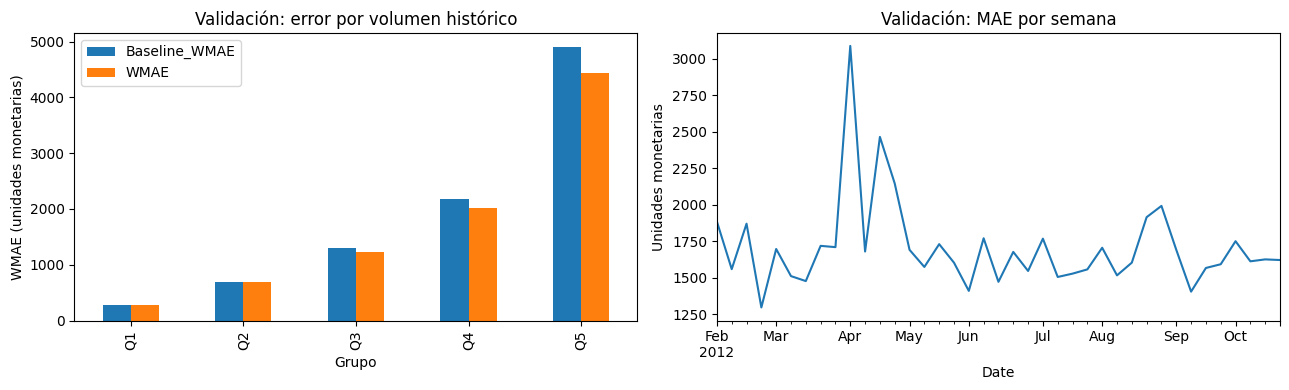

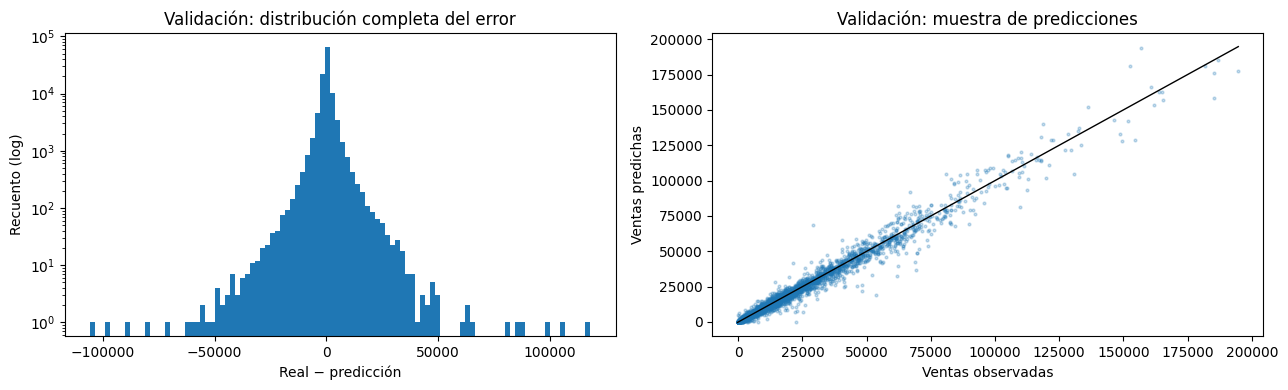

,Store,Dept,Date,Weekly_Sales,Prediction,Error,Lag_52,Gate_Weight
34960,14,1,2012-04-06,156677.000000,38625.864990,118051.135010,41257.359375,0.619894
32115,13,1,2012-04-20,30200.669922,136099.943359,-105899.273438,154137.875000,0.988734
51268,20,1,2012-04-06,156234.281250,50397.558105,105836.723145,55117.781250,0.801714
32113,13,1,2012-04-06,150715.437500,52767.248291,97948.189209,51889.980469,0.774180
34962,14,1,2012-04-20,18877.130859,115899.285156,-97022.154297,133744.515625,0.951728
51270,20,1,2012-04-20,24247.259766,112565.013672,-88317.753906,143220.953125,0.987902
59343,23,1,2012-04-06,120877.000000,33947.157227,86929.842773,37220.410156,0.659523
32213,13,3,2012-09-07,114230.601562,28917.291016,85313.310547,27062.400391,0.445000
23903,10,1,2012-04-06,120131.351562,39124.950043,81006.401520,39469.628906,0.563695
37452,14,92,2012-08-24,145009.718750,225628.223633,-80618.504883,241120.000000,0.999427


In [12]:
cutpoints = np.unique(train_covered[BASELINE].quantile([.2,.4,.6,.8]).to_numpy())
val_results['Volume'] = pd.cut(val_results[BASELINE],[-np.inf,*cutpoints,np.inf],
                              labels=[f'Q{i+1}' for i in range(len(cutpoints)+1)])
group_tables = {}
for column in ['Volume','IsHoliday','Lag_52_imputed','Store','Dept']:
    records = []
    for group,sub in val_results.groupby(column,observed=True):
        base = metrics(sub,sub[BASELINE]); result = metrics(sub,sub['Prediction'])
        records.append({'Grupo':str(group),**result,'Baseline_WMAE':base['WMAE'],
                        'Mejora_WMAE_pct':100*(base['WMAE']-result['WMAE'])/base['WMAE'] if base['WMAE'] else np.nan,
                        'Proporción_MLP':sub['Gate_Weight'].mean()})
    table = pd.DataFrame(records)
    group_tables[column] = table
    table.to_csv(OUTPUT/f'validation_by_{column}.csv',index=False)
    display(Markdown(f'**Validación por {column}**'))
    display(table if len(table)<12 else table.sort_values('WMAE',ascending=False).head(10))

fig,axes = plt.subplots(1,2,figsize=(13,4))
group_tables['Volume'].set_index('Grupo')[['Baseline_WMAE','WMAE']].plot.bar(ax=axes[0])
axes[0].set(title='Validación: error por volumen histórico',ylabel='WMAE (unidades monetarias)')
weekly = val_results.assign(AE=lambda d:d['Error'].abs()).groupby('Date')['AE'].mean()
weekly.plot(ax=axes[1],title='Validación: MAE por semana',ylabel='Unidades monetarias')
plt.tight_layout();fig.savefig(OUTPUT/'validation_volume_weekly.png',dpi=160);plt.show()
fig,axes = plt.subplots(1,2,figsize=(13,4))
val_results['Error'].plot.hist(bins=100,ax=axes[0],logy=True)
axes[0].set(title='Validación: distribución completa del error',xlabel='Real − predicción',ylabel='Recuento (log)')
plot_sample = val_results.sample(min(5000,len(val_results)),random_state=SEED)
axes[1].scatter(plot_sample[TARGET],plot_sample['Prediction'],s=4,alpha=.25)
lo = min(plot_sample[TARGET].min(),plot_sample['Prediction'].min())
hi = max(plot_sample[TARGET].max(),plot_sample['Prediction'].max())
axes[1].plot([lo,hi],[lo,hi],color='black',linewidth=1)
axes[1].set(title='Validación: muestra de predicciones',xlabel='Ventas observadas',ylabel='Ventas predichas')
plt.tight_layout();fig.savefig(OUTPUT/'validation_errors.png',dpi=160);plt.show()
display(val_results.loc[val_results['Error'].abs().nlargest(10).index,
                        KEYS+[TARGET,'Prediction','Error',BASELINE,'Gate_Weight']])

### 3.1. Interpretación del comportamiento en validación

El análisis por quintiles de `Lag_52` muestra una relación clara entre el volumen de ventas y la intervención de la red neuronal. En el quintil inferior, el peso medio de la puerta sobre la MLP es del **3,02 %**, con una mejora de WMAE del **0,10 %** frente a la referencia anual. En el quintil superior, el peso medio alcanza el **53,09 %** y la mejora relativa asciende al **9,58 %**. La arquitectura conserva en mayor medida la referencia histórica cuando las ventas son reducidas y concede más protagonismo a la corrección aprendida cuando aumenta el volumen. El peso de la puerta es continuo: no debe interpretarse como un porcentaje de observaciones asignadas exclusivamente a la MLP.

En las semanas festivas, la reducción relativa del WMAE respecto a `Lag_52` es del **12,31 %**, frente al **6,33 %** en semanas no festivas. Estas comparaciones corresponden a la validación utilizada durante la selección. Por otra parte, las **893 observaciones** con `Lag_52` reconstruido muestran una mejora reducida (**0,37 %**), frente al **7,62 %** de las observaciones con retardo original. La diferencia de escalas y composición de ambos grupos impide atribuir el menor error absoluto de las filas reconstruidas a una mayor precisión de la reconstrucción.

## 4. Reentrenamiento del Soft MoE con todo el histórico

Se unen entrenamiento y validación, se reconstruyen las variables con el histórico etiquetado completo y se ajustan **nuevos transformadores únicamente sobre esos datos**. Se inicializa una red nueva con la misma arquitectura del Soft MoE + FE seleccionado.

No se utiliza el test para ajustar transformadores, optimizar hiperparámetros ni detener el entrenamiento. Como no existe una validación independiente para el ajuste final, se fija previamente el número de épocas a partir de la época con menor `val_loss` del experimento de selección. La red final no utiliza `EarlyStopping` sobre test. La pérdida sigue siendo MAE ponderado (peso 5 en festivos).

In [13]:
if 'Epoch' in val_history.columns:
    epoch_numbers=pd.to_numeric(val_history['Epoch'],errors='raise').to_numpy(dtype=int)
else:
    epoch_numbers=np.arange(1,len(val_history)+1)
if 'val_loss' not in val_history.columns:
    raise ValueError('El historial de selección no contiene val_loss.')
values=val_history['val_loss'].to_numpy(dtype=float)
assert len(values)>0 and np.isfinite(values).all()
FINAL_EPOCHS=int(epoch_numbers[np.argmin(values)])
assert FINAL_EPOCHS>0
print('Época seleccionada por validación:',FINAL_EPOCHS)

full_enriched=enrich(full_raw,history_full)
full_covered=full_enriched.loc[full_enriched[BASELINE].notna()].copy()
assert not full_covered.duplicated(KEYS).any()
assert np.isfinite(full_covered[RESIDUAL_TARGET]).all()
assert full_covered['Date'].max()<test_raw['Date'].min()
final_policy={'epochs':FINAL_EPOCHS,'selection_signature':selection_signature,
              'basis':'best val_loss of original Soft MoE + FE',
              'optimizer':'Adam lr=0.001','batch_size':256}
final_signature=object_signature({'config':CONFIG,'versions':VERSIONS,'policy':final_policy,
    'data':frame_signature(full_covered,KEYS+[c for c in FEATURES if c not in KEYS]+[RESIDUAL_TARGET]),
    'history':frame_signature(full_raw,KEYS+[TARGET])})

def save_final(model,preprocessor,scaler,history):
    (FINAL_MODEL/'metadata.json').unlink(missing_ok=True)
    model.save_weights(str(FINAL_MODEL/'model.weights.h5'))
    joblib.dump(preprocessor,FINAL_MODEL/'preprocessor.joblib')
    joblib.dump(scaler,FINAL_MODEL/'target_scaler.joblib')
    history.to_csv(FINAL_MODEL/'history.csv',index=False)
    (FINAL_MODEL/'config.json').write_text(json.dumps(CONFIG,indent=2))
    names=['model.weights.h5','preprocessor.joblib','target_scaler.joblib','history.csv','config.json']
    meta={'signature':final_signature,'versions':VERSIONS,'policy':final_policy,
          'hashes':{name:file_hash(FINAL_MODEL/name) for name in names}}
    (FINAL_MODEL/'metadata.json').write_text(json.dumps(meta,indent=2))
    return meta

def load_final():
    names=['model.weights.h5','preprocessor.joblib','target_scaler.joblib','history.csv','config.json']
    if not all((FINAL_MODEL/name).exists() for name in names+['metadata.json']): return None
    try:
        meta=json.loads((FINAL_MODEL/'metadata.json').read_text())
        if meta['signature']!=final_signature or meta['versions']!=VERSIONS: return None
        if any(meta['hashes'][name]!=file_hash(FINAL_MODEL/name) for name in names): return None
        pre=joblib.load(FINAL_MODEL/'preprocessor.joblib')
        scaler=joblib.load(FINAL_MODEL/'target_scaler.joblib')
        width=pre.transform(full_covered[FEATURES].head(8)).shape[1]
        model=make_moe(width,baseline_scaled_value(scaler))
        model.load_weights(str(FINAL_MODEL/'model.weights.h5'))
        return model,pre,scaler,pd.read_csv(FINAL_MODEL/'history.csv'),meta
    except (OSError,ValueError,KeyError,TypeError,EOFError,pickle.UnpicklingError) as exc:
        print('Artefactos definitivos incompatibles:',type(exc).__name__,str(exc)[:160])
        return None

loaded=None if TRAIN else load_final()
if loaded is None:
    print('Entrenando Soft MoE + FE definitivo desde cero...')
    final_preprocessor=make_preprocessor().fit(full_covered[FEATURES])
    final_scaler=StandardScaler().fit(full_covered[[RESIDUAL_TARGET]])
    X=final_preprocessor.transform(full_covered[FEATURES]).astype('float32')
    y=final_scaler.transform(full_covered[[RESIDUAL_TARGET]]).astype('float32')
    final_model=make_moe(X.shape[1],baseline_scaled_value(final_scaler))
    fitted=final_model.fit(X,y,sample_weight=weights(full_covered),
        epochs=FINAL_EPOCHS,batch_size=256,verbose=1)
    final_history=pd.DataFrame(fitted.history)
    final_metadata=save_final(final_model,final_preprocessor,final_scaler,final_history)
else:
    final_model,final_preprocessor,final_scaler,final_history,final_metadata=loaded
    print('Soft MoE + FE definitivo: pesos y transformadores recuperados.')
check_bundle(final_model,final_preprocessor,final_scaler,full_covered)
for path, data in [(OUTPUT/'full_history_features.parquet',full_enriched),
                   (OUTPUT/'test_features_audited.parquet',test_rebuilt)]:
    if TRAIN or not path.exists():
        data.to_parquet(path,index=False)
policy_path = OUTPUT/'final_training_policy.json'
if TRAIN or not policy_path.exists():
    policy_path.write_text(json.dumps(final_policy,indent=2))
display(pd.DataFrame([coverage(full_enriched,'Histórico completo')]))
print('Observaciones de entrenamiento definitivo:',len(full_covered))

Época seleccionada por validación: 10


/tmp/ipykernel_707/551150651.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_707/551150651.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_707/551150651.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


Soft MoE + FE definitivo: pesos y transformadores recuperados.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,Conjunto,Total,Con_Lag52,Cobertura
0,Histórico completo,421570,263446,0.624916


Observaciones de entrenamiento definitivo: 263446


## 5. Predicciones sobre el conjunto de test

Se utiliza la red definitiva reentrenada con todo el histórico y sus propios transformadores. Para cada fila con `Lag_52` disponible se suma la corrección residual del Soft MoE al valor anual. Las filas sin referencia anual permanecen identificadas como no cubiertas: no se les asignan predicciones inventadas.

Se conservan todas las claves del test original en los archivos de salida y se analizan las distribuciones de las predicciones, **sin calcular errores** porque no existen ventas observadas en test.

,Conjunto,Total,Con_Lag52,Cobertura
0,Test sin etiquetas,115064,113915,0.990014


,Weekly_Sales_Prediction,Lag_52,Correction
count,113915.000000,113915.000000,113915.000000
mean,16999.934386,16647.555919,352.378448
std,23704.242276,23745.161463,2632.879395
min,-497.523827,-498.000000,-78851.765625
1%,18.373763,9.440000,-9289.400937
50%,8323.155640,7844.689941,182.622330
99%,108350.022617,110376.552344,7042.614805
max,637338.452148,649770.187500,23100.691406


Negativas: 261 Filas señaladas para inspección: 454
No se calculan métricas de precisión sobre test.


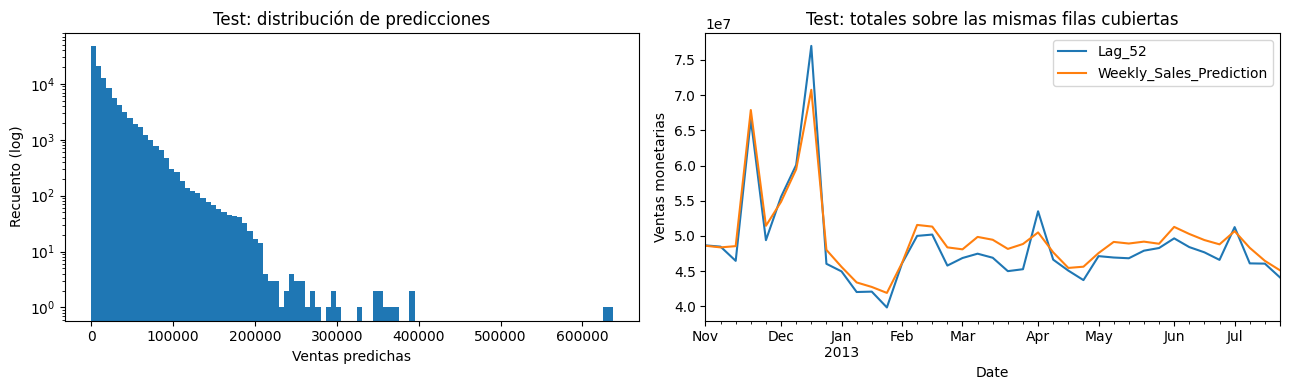

In [14]:
test_covered = test_rebuilt.loc[test_rebuilt[BASELINE].notna()].copy()
test_prediction,test_correction = predict_system(final_model,final_preprocessor,final_scaler,test_covered)
test_predictions = test_covered[KEYS+[BASELINE,'IsHoliday','Lag_52_imputed']].copy()
test_predictions['Weekly_Sales_Prediction'] = test_prediction
test_predictions['Correction'] = test_correction
assert np.isfinite(test_prediction).all()
assert not test_predictions.duplicated(KEYS).any()
all_predictions = test_raw[KEYS].merge(test_predictions,on=KEYS,how='left',validate='one_to_one',sort=False)
pd.testing.assert_frame_equal(all_predictions[KEYS].reset_index(drop=True),test_raw[KEYS].reset_index(drop=True))
all_predictions['Covered'] = all_predictions['Weekly_Sales_Prediction'].notna()
all_predictions['Exclusion_Reason'] = np.where(all_predictions['Covered'],'','Sin Lag_52 observado o reconstruible')
assert all_predictions['Covered'].sum() == len(test_predictions)
prediction_outputs = [
    (OUTPUT/'test_predictions_all_keys.parquet', all_predictions, 'parquet'),
    (OUTPUT/'test_predictions_all_keys.csv', all_predictions, 'csv'),
    (OUTPUT/'test_predictions_covered.parquet', test_predictions, 'parquet'),
    (OUTPUT/'test_predictions_covered.csv', test_predictions, 'csv'),
    (OUTPUT/'test_excluded.csv', all_predictions.loc[~all_predictions['Covered'],KEYS+['Exclusion_Reason']], 'csv')
]
for path, data, fmt in prediction_outputs:
    if TRAIN or not path.exists():
        if fmt == 'parquet': data.to_parquet(path,index=False)
        else: data.to_csv(path,index=False)

historical_low,historical_high = full_raw[TARGET].quantile([.001,.999]).to_numpy()
anomalies = test_predictions.loc[(test_prediction<0)|(test_prediction<historical_low)|(test_prediction>historical_high)]
if TRAIN or not (OUTPUT/'test_predictions_to_inspect.csv').exists():
    anomalies.to_csv(OUTPUT/'test_predictions_to_inspect.csv',index=False)
display(pd.DataFrame([coverage(test_rebuilt,'Test sin etiquetas')]))
display(test_predictions[['Weekly_Sales_Prediction',BASELINE,'Correction']].describe(percentiles=[.01,.5,.99]))
print('Negativas:',int((test_prediction<0).sum()),'Filas señaladas para inspección:',len(anomalies))
print('No se calculan métricas de precisión sobre test.')

fig,axes = plt.subplots(1,2,figsize=(13,4))
test_predictions['Weekly_Sales_Prediction'].plot.hist(bins=100,logy=True,ax=axes[0])
axes[0].set(title='Test: distribución de predicciones',xlabel='Ventas predichas',ylabel='Recuento (log)')
test_predictions.groupby('Date')[[BASELINE,'Weekly_Sales_Prediction']].sum().plot(ax=axes[1])
axes[1].set(title='Test: totales sobre las mismas filas cubiertas',ylabel='Ventas monetarias')
plt.tight_layout();
if TRAIN or not (OUTPUT/'test_descriptive.png').exists():
    fig.savefig(OUTPUT/'test_descriptive.png',dpi=160)
plt.show()

### 5.1. Cobertura y coherencia de las predicciones

El modelo definitivo genera predicciones para **113.915 de las 115.064 observaciones** del conjunto de test (**99,00 % de cobertura**). Las **1.149 filas** restantes carecen de una referencia anual utilizable y se mantienen identificadas como no cubiertas. Se considera una cobertura satisfactoria para este cierre experimental; no se incorpora una estrategia alternativa de imputación o predicción sin haberla validado previamente.

Se obtienen **261 predicciones negativas**, equivalentes al **0,23 %** de las observaciones cubiertas. Su mediana es **−11,75** y el mínimo **−497,52**; solo **15** son inferiores a −100 y ninguna es inferior a −1.000. En varios de los casos más extremos, `Lag_52` ya presenta valores negativos, de modo que la red conserva en gran medida una referencia histórica compatible con ventas netas negativas. También existen algunos cambios de signo debidos a correcciones residuales. Se mantienen las predicciones originales, puesto que no se ha comprobado en validación que truncarlas a cero mejore el resultado.

La distribución de las predicciones y su comparación descriptiva con `Lag_52` **no permiten valorar el acierto** de la red definitiva: en test no se conocen las ventas reales.

## 6. Interpretabilidad del modelo definitivo mediante SHAP

Se explica la **corrección residual del Soft MoE completo**, incluida la puerta aprendida, no la predicción total. Se comparan las contribuciones en dos grupos de test: semanas fuera de las campañas seleccionadas y semanas correspondientes a Thanksgiving (23/11/2012) o a las tres semanas prenavideñas (07, 14 y 21/12/2012), identificadas como relevantes en el EDA.

Los dos grupos utilizan el mismo fondo histórico, compuesto por observaciones de campañas equivalentes y de otros períodos. Se calcula la importancia media absoluta y la distribución de contribuciones para cada grupo. Las diferencias son **descriptivas**: SHAP no demuestra causalidad ni permite medir rendimiento en el test sin variable objetivo. La etiqueta «ordinario» significa «fuera de estas campañas», no necesariamente `IsHoliday=False`.

,Date,SHAP_Periodo,N
3,2012-11-23,Campanas,2929
5,2012-12-07,Campanas,2949
6,2012-12-14,Campanas,2952
7,2012-12-21,Campanas,2962


Observaciones cubiertas por grupo:


,N
Grupo,
Ordinario,102123
Campanas,11792


SHAP Ordinario: resultados recuperados de caché.
Ordinario: 128 observaciones; error máximo de aditividad = 0.000488


### SHAP: Ordinario

,Variable,Mean_abs_SHAP
1,Dept,796.206599
5,Lag_52,617.313797
9,Lag_52_Deviation,469.278450
0,Store,433.701118
23,TimeIndex,331.589656
22,Size,179.724818
7,Lag_Local_Mean,154.845325
6,Lag_53,151.999086
4,Lag_51,134.520533
16,Delta_Fuel_Price,107.939860


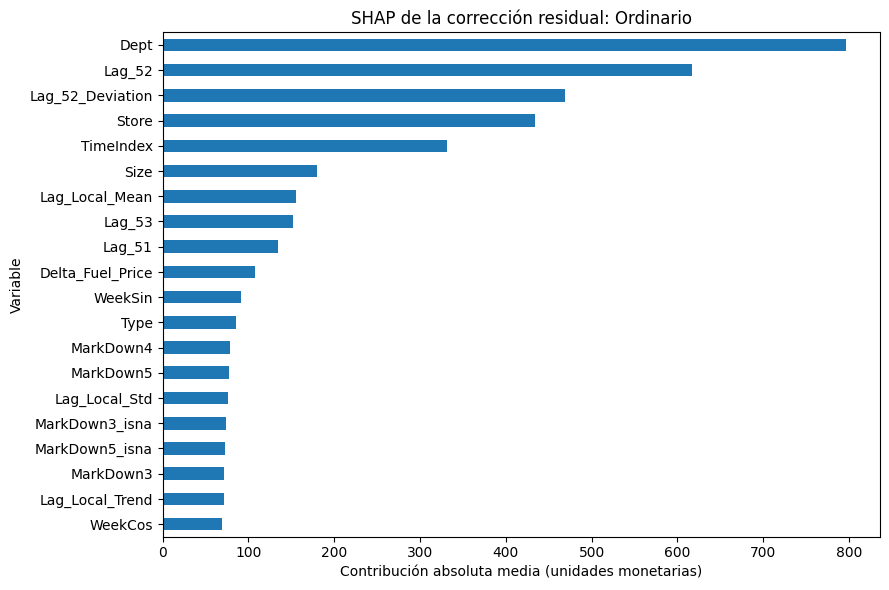

/tmp/ipykernel_707/2201616080.py:183: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


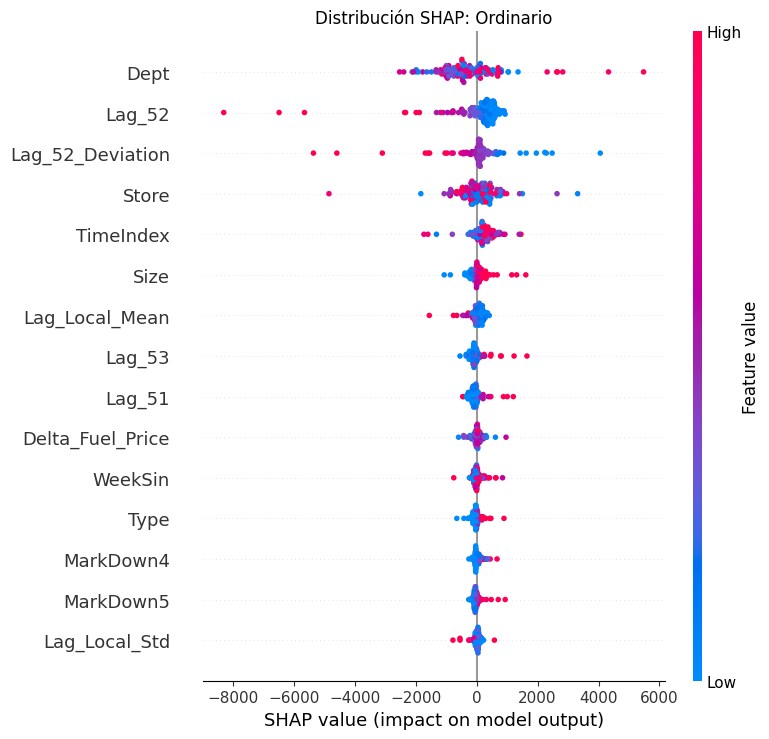

SHAP Campanas: resultados recuperados de caché.
Campanas: 128 observaciones; error máximo de aditividad = 0.000030


### SHAP: Campanas

,Variable,Mean_abs_SHAP
9,Lag_52_Deviation,1363.272586
5,Lag_52,1212.911425
1,Dept,1111.929471
10,Lag_Local_Std,785.292759
0,Store,681.198309
19,MarkDown3,392.296808
23,TimeIndex,296.887212
22,Size,256.789104
8,Lag_Local_Trend,224.266594
7,Lag_Local_Mean,219.866434


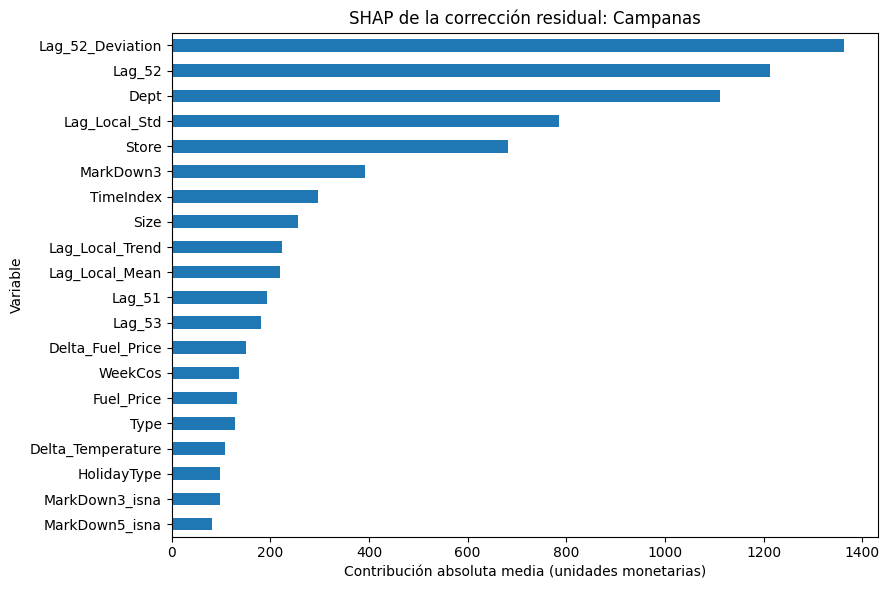

/tmp/ipykernel_707/2201616080.py:183: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


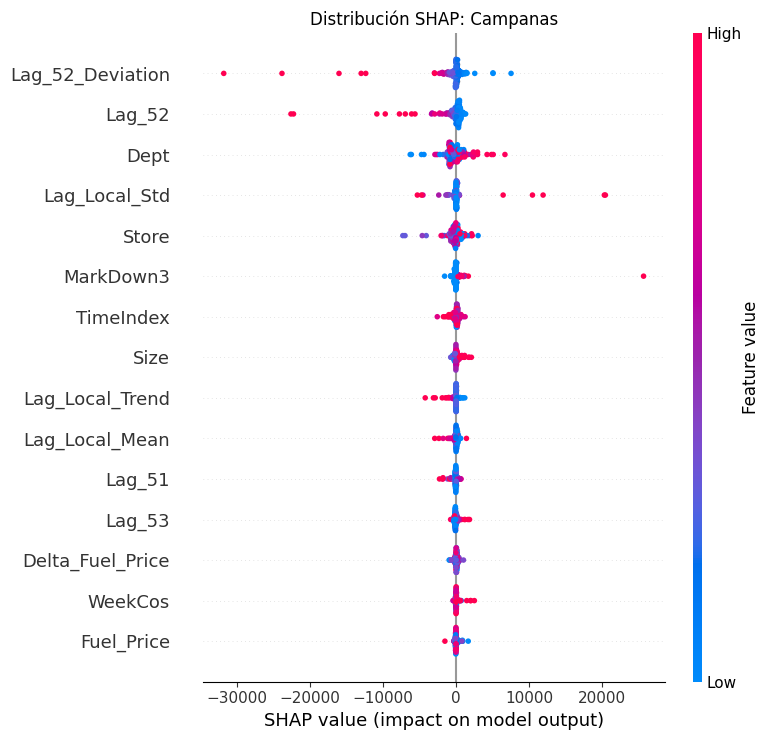

### Comparación de importancias SHAP

,Ordinario,Campanas,Diferencia_Campanas_menos_Ordinario
Variable,,,
Lag_52_Deviation,469.28,1363.27,893.99
Lag_52,617.31,1212.91,595.60
Dept,796.21,1111.93,315.72
Lag_Local_Std,75.88,785.29,709.41
Store,433.70,681.20,247.50
MarkDown3,71.55,392.30,320.74
TimeIndex,331.59,296.89,-34.70
Size,179.72,256.79,77.06
Lag_Local_Trend,71.49,224.27,152.78


Las diferencias son descriptivas: muestras de tamaño limitado, no estimaciones causales ni medidas de rendimiento.


In [15]:
if RUN_SHAP:
    import shap

    # Campañas identificadas como relevantes en el EDA (test de 2012).
    thanksgiving = {pd.Timestamp('2012-11-23')}
    prenavidad = {pd.Timestamp(d) for d in ['2012-12-07', '2012-12-14', '2012-12-21']}
    campaign_dates = thanksgiving | prenavidad

    high_test = test_covered.copy()
    if high_test.empty:
        raise ValueError('No hay observaciones de test cubiertas.')

    high_test['SHAP_Periodo'] = np.where(
        high_test['Date'].isin(campaign_dates), 'Campanas', 'Ordinario'
    )
    # La categoría "ordinario" se refiere aquí a "fuera de las campañas seleccionadas".
    # No equivale necesariamente a IsHoliday=False (p. ej., Super Bowl).
    counts = (high_test.groupby(['Date', 'SHAP_Periodo'], observed=True)
              .size().reset_index(name='N'))
    display(counts[counts['Date'].isin(campaign_dates)])
    print('Observaciones cubiertas por grupo:')
    display(high_test['SHAP_Periodo'].value_counts().rename_axis('Grupo').to_frame('N'))

    # Fondo común de 32 registros: mitad histórico de campañas equivalentes,
    # mitad de otras fechas. Se utiliza el mismo fondo en los dos SHAP.
    historic_campaign_dates = {
        pd.Timestamp(d) for d in [
            '2010-11-26', '2010-12-10', '2010-12-17', '2010-12-24',
            '2011-11-25', '2011-12-09', '2011-12-16', '2011-12-23',
            '2012-11-23', '2012-12-07', '2012-12-14', '2012-12-21'
        ]
    }
    historic_campaign = full_covered[full_covered['Date'].isin(historic_campaign_dates)]
    historic_other = full_covered[~full_covered['Date'].isin(historic_campaign_dates)]
    bg_n = min(SHAP_BACKGROUND, len(full_covered))
    bg_campaign_n = min(bg_n // 2, len(historic_campaign))
    bg_other_n = min(bg_n - bg_campaign_n, len(historic_other))
    background = pd.concat([
        historic_campaign.sample(bg_campaign_n, random_state=SEED),
        historic_other.sample(bg_other_n, random_state=SEED + 1)
    ], ignore_index=True)
    if len(background) != bg_n:
        raise ValueError('No se pudo construir el fondo SHAP común solicitado.')
    if bg_campaign_n == 0 or bg_other_n == 0:
        raise ValueError('El fondo debe contener períodos ordinarios y de campaña.')
    if TRAIN or not (OUTPUT / 'shap/background_keys_comun.csv').exists():
        background[KEYS].to_csv(OUTPUT / 'shap/background_keys_comun.csv', index=False)

    category_values = {
        c: list(pd.unique(pd.concat([full_covered[c], high_test[c]]).dropna()))
        for c in CAT
    }

    def encode_shap(df):
        out = df[FEATURES].copy()
        for c in CAT:
            out[c] = pd.Categorical(out[c], categories=category_values[c]).codes
        return out.to_numpy(dtype=float)

    def decode_shap(array):
        out = pd.DataFrame(np.asarray(array), columns=FEATURES)
        for c in CAT:
            ids = np.rint(out[c].to_numpy()).astype(int)
            if ((ids < -1) | (ids >= len(category_values[c]))).any():
                raise ValueError(f'Código categórico no válido en {c}.')
            out[c] = [category_values[c][i] if i >= 0 else np.nan for i in ids]
        return out

    def shap_predict(array):
        frame = decode_shap(array)
        X = final_preprocessor.transform(frame[FEATURES]).astype('float32')
        values = np.concatenate([
            np.asarray(final_model(X[i:i+4096], training=False)).reshape(-1, 1)
            for i in range(0, len(X), 4096)
        ])
        return final_scaler.inverse_transform(values).ravel()

    bg = encode_shap(background)
    results_shap = {}
    importance_tables = []

    for group_name in ['Ordinario', 'Campanas']:
        population = high_test[high_test['SHAP_Periodo'] == group_name]
        if population.empty:
            print(f'Sin observaciones para {group_name}; se omite el análisis.')
            continue
        explained = population.sample(
            min(SHAP_SAMPLES, len(population)),
            random_state=SEED + (11 if group_name == 'Ordinario' else 12)
        ).copy()
        group_dir = OUTPUT / 'shap' / group_name.lower()
        group_dir.mkdir(parents=True, exist_ok=True)
        if TRAIN or not (group_dir / 'explained_keys.csv').exists():
            explained[KEYS].to_csv(group_dir / 'explained_keys.csv', index=False)
        explain_x = encode_shap(explained)

        np.testing.assert_allclose(
            shap_predict(explain_x),
            predict_residual(final_model, final_preprocessor, final_scaler, explained),
            rtol=1e-5, atol=1e-3
        )

        signature = object_signature({
            'model': final_metadata['hashes'], 'shap': shap.__version__,
            'background': frame_signature(background, KEYS + [c for c in FEATURES if c not in KEYS]),
            'explained': frame_signature(explained, KEYS + [c for c in FEATURES if c not in KEYS]),
            'permutations': SHAP_PERMUTATIONS, 'seed': SEED, 'group': group_name
        })
        metadata_path = group_dir / 'metadata.json'
        values_path = group_dir / 'values.npz'
        reuse = False
        if not TRAIN and metadata_path.exists() and values_path.exists():
            cached = json.loads(metadata_path.read_text())
            reuse = (cached.get('signature') == signature and
                     cached.get('array_hash') == file_hash(values_path))

        if reuse:
            with np.load(values_path) as stored:
                shap_values = stored['values']
                base_values = stored['base_values']
            print(f'SHAP {group_name}: resultados recuperados de caché.')
        else:
            explainer = shap.PermutationExplainer(
                shap_predict, bg, feature_names=FEATURES, seed=SEED
            )
            explanation = explainer(
                explain_x,
                max_evals=SHAP_PERMUTATIONS * (2 * len(FEATURES) + 1),
                batch_size=128, silent=False
            )
            shap_values = np.asarray(explanation.values)
            base_values = np.asarray(explanation.base_values).reshape(-1)
            np.savez_compressed(values_path, values=shap_values, base_values=base_values)
            metadata_path.write_text(json.dumps({
                'signature': signature, 'array_hash': file_hash(values_path),
                'model_signature': final_signature,
                'output': 'residual monetary units',
                'group': group_name, 'background_n': len(background),
                'explained_n': len(explained), 'permutations': SHAP_PERMUTATIONS,
                'seed': SEED, 'shap_version': shap.__version__
            }, indent=2))

        residual = shap_predict(explain_x)
        max_error = np.abs(base_values + shap_values.sum(axis=1) - residual).max()
        np.testing.assert_allclose(
            base_values + shap_values.sum(axis=1), residual, rtol=1e-4, atol=.05
        )
        print(f'{group_name}: {len(explained)} observaciones; '
              f'error máximo de aditividad = {max_error:.6f}')

        importance = (pd.DataFrame({
            'Variable': FEATURES,
            'Mean_abs_SHAP': np.abs(shap_values).mean(axis=0)
        }).sort_values('Mean_abs_SHAP', ascending=False))
        if TRAIN or not (group_dir / 'importance.csv').exists():
            importance.to_csv(group_dir / 'importance.csv', index=False)
        display(Markdown(f'### SHAP: {group_name}'))
        display(importance.head(15))
        importance_tables.append(importance.set_index('Variable')['Mean_abs_SHAP'].rename(group_name))

        # Identificadores diferenciados de las columnas de contribución.
        identifiers = explained[KEYS].reset_index(drop=True).rename(
            columns={'Store': 'Store_ID', 'Dept': 'Dept_ID'}
        )
        contributions = pd.concat([
            identifiers, pd.DataFrame(shap_values, columns=FEATURES)
        ], axis=1)
        assert contributions.columns.is_unique
        if TRAIN or not (group_dir / 'contributions.parquet').exists():
            contributions.to_parquet(group_dir / 'contributions.parquet', index=False)

        fig, ax = plt.subplots(figsize=(9, 6))
        importance.head(20).iloc[::-1].plot.barh(
            x='Variable', y='Mean_abs_SHAP', legend=False, ax=ax
        )
        ax.set(title=f'SHAP de la corrección residual: {group_name}',
               xlabel='Contribución absoluta media (unidades monetarias)')
        plt.tight_layout()
        if TRAIN or not (group_dir / 'importance.png').exists():
            fig.savefig(group_dir / 'importance.png', dpi=160)
        plt.show()

        shap.summary_plot(
            shap_values, explain_x, feature_names=FEATURES,
            max_display=15, show=False
        )
        plt.title(f'Distribución SHAP: {group_name}')
        plt.tight_layout()
        if TRAIN or not (group_dir / 'beeswarm.png').exists():
            plt.savefig(group_dir / 'beeswarm.png', dpi=160, bbox_inches='tight')
        plt.show()

        results_shap[group_name] = {
            'n_population': len(population), 'n_explained': len(explained),
            'importance': importance, 'explained': explained,
            'values': shap_values, 'base_values': base_values
        }

    if len(importance_tables) == 2:
        comparison = pd.concat(importance_tables, axis=1)
        comparison['Diferencia_Campanas_menos_Ordinario'] = (
            comparison['Campanas'] - comparison['Ordinario']
        )
        comparison = comparison.sort_values('Campanas', ascending=False)
        if TRAIN or not (OUTPUT / 'shap/comparison.csv').exists():
            comparison.to_csv(OUTPUT / 'shap/comparison.csv')
        display(Markdown('### Comparación de importancias SHAP'))
        display(comparison.round(2))
        print('Las diferencias son descriptivas: muestras de tamaño limitado, '
              'no estimaciones causales ni medidas de rendimiento.')
else:
    print('SHAP desactivado expresamente: el análisis interpretativo queda pendiente.')


### 6.1. Lectura de la importancia global: coherencia con la arquitectura y el EDA

SHAP se aplica a la **corrección residual del Soft MoE completo**, incluida la combinación aprendida por la puerta, y no directamente a las ventas predichas. La elevada importancia de `Lag_52` es coherente con la formulación del modelo, que utiliza la referencia anual como punto de partida; su contribución SHAP representa, sin embargo, cómo ese retardo condiciona **la corrección**, no la aportación aritmética directa de `Lag_52` a las ventas finales.

En las semanas fuera de las campañas seleccionadas destacan `Dept` (**796,21**), `Lag_52` (**617,31**), `Lag_52_Deviation` (**469,28**), `Store` (**433,70**) y `TimeIndex` (**331,59**). El protagonismo de los identificadores comerciales resulta compatible con la heterogeneidad entre departamentos y tiendas documentada en el EDA. Las variables históricas, por su parte, muestran que la corrección no depende exclusivamente del nivel anual de ventas, sino también de su evolución y desviaciones.

En las campañas comerciales sobresalen `Lag_52_Deviation` (**1.363,27**), `Lag_52` (**1.212,91**), `Dept` (**1.111,93**), `Lag_Local_Std` (**785,29**) y `Store` (**681,20**). Frente al grupo ordinario, aumenta especialmente la importancia de la desviación anual, la variabilidad local y `MarkDown3` (de **71,55** a **392,30**). Esto es compatible con los picos estacionales, la disparidad departamental y la información promocional analizados en el EDA. La importancia de `MarkDown3` no demuestra un efecto causal de las promociones.

Los gráficos de dispersión muestran contribuciones más extremas en campañas. Esta diferencia puede estar relacionada tanto con el comportamiento excepcional de algunas series como con su escala de ventas; **no es evidencia de un peor rendimiento predictivo**. La clasificación de importancias tampoco debe interpretarse como causal: variables relacionadas, como los retardos y sus derivados, pueden compartir información.

### 6.2. Thanksgiving y campaña prenavideña: examen de los casos extremos

Para profundizar en el grupo de campañas se desagregan las **128 observaciones explicadas**: **23** corresponden a Thanksgiving y **105** a las tres semanas prenavideñas. La muestra es desigual y, especialmente en Thanksgiving, reducida; por ello la comparación se considera **descriptiva**.

`Lag_52` mantiene una importancia semejante en ambos grupos (**1.231,70** en Thanksgiving y **1.208,80** en Prenavidad). `Lag_52_Deviation` alcanza **1.825,32** y **1.262,06**, respectivamente. `Dept` tiene mayor importancia media en Prenavidad (**1.218,99** frente a **623,16**), en consonancia con las diferencias departamentales identificadas en el EDA. `MarkDown3` destaca especialmente en Thanksgiving (**1.681,66** frente a **109,86**), aunque el examen individual revela que su promedio está fuertemente influido por valores extremos.

El caso más destacado corresponde a la **tienda 4, departamento 72, en Thanksgiving del 23/11/2012**: `Lag_52_Deviation` aporta **−31.855,98** a la corrección residual explicada y `MarkDown3` **+25.714,04**, respecto al fondo SHAP. El departamento 72 ya había mostrado incrementos especialmente pronunciados durante Thanksgiving en el EDA. Otro caso notable es la **tienda 19, departamento 72, el 21/12/2012**, con contribuciones de **−23.871,37** en `Lag_52_Deviation`, **−22.640,08** en `Lag_52` y **+20.477,99** en `Lag_Local_Std`. La coexistencia de contribuciones de signo contrario pone de manifiesto la interacción de señales que utiliza el modelo; no debe traducirse en efectos causales ni en cambios observados de ventas.

La interpretación está limitada por el número de observaciones explicadas (**128 por grupo principal**), el fondo de referencia común (**32 registros**) y la sensibilidad de la importancia media absoluta a los casos extremos. Asimismo, el grupo denominado «ordinario» comprende todas las semanas fuera de las cuatro fechas de campaña seleccionadas, por lo que **no equivale estrictamente a `IsHoliday=False`**. SHAP describe el funcionamiento del modelo final sobre test sin etiquetas, pero no su precisión.

### 6.3. Desglose reproducible de las campañas sin recalcular SHAP

La siguiente celda recupera el archivo de contribuciones ya guardado y obtiene la tabla de importancia media absoluta por campaña y los casos extremos. **No vuelve a ejecutar el explicador SHAP**. Si los archivos de salida existen y `TRAIN=False`, se conservan; únicamente se generan los que falten.

In [16]:
# Comparación descriptiva Thanksgiving / Prenavidad a partir de SHAP guardado.
# No se invoca el explainer: se leen contribuciones ya calculadas.
subgroup_path = OUTPUT/'shap/campanas/contributions.parquet'
if RUN_SHAP and subgroup_path.exists():
    subgroup = pd.read_parquet(subgroup_path).copy()
    subgroup['Date'] = pd.to_datetime(subgroup['Date'])
    subgroup['Campana'] = np.select([
        subgroup['Date'].eq(pd.Timestamp('2012-11-23')),
        subgroup['Date'].isin(pd.to_datetime(['2012-12-07','2012-12-14','2012-12-21']))
    ],['Thanksgiving','Prenavidad'],default='Otros')
    assert not subgroup['Campana'].eq('Otros').any()
    display(subgroup['Campana'].value_counts().rename('Observaciones').to_frame())
    campaign_rows=[]
    for name, group in subgroup.groupby('Campana'):
        for variable in FEATURES:
            values=group[variable]
            campaign_rows.append({'Campana':name,'Variable':variable,'N':len(group),
                                  'Mean_abs_SHAP':values.abs().mean(),
                                  'Mean_SHAP':values.mean(),'Max_abs_SHAP':values.abs().max()})
    detail=pd.DataFrame(campaign_rows)
    campaign_comparison=detail.pivot(index='Variable',columns='Campana',values='Mean_abs_SHAP')
    campaign_comparison['Suma_descriptiva']=campaign_comparison.sum(axis=1)
    campaign_comparison=campaign_comparison.sort_values('Suma_descriptiva',ascending=False)
    display(campaign_comparison.head(15).round(2))
    extreme=subgroup.melt(id_vars=['Store_ID','Dept_ID','Date','Campana'],
                          value_vars=FEATURES,var_name='Variable',value_name='SHAP')
    extreme['Abs_SHAP']=extreme['SHAP'].abs()
    extreme=extreme.sort_values('Abs_SHAP',ascending=False)
    display(extreme.head(15).round(2))
    for path, frame in [
        (OUTPUT/'shap/campanas/importance_by_campaign.csv',detail),
        (OUTPUT/'shap/campanas/comparison_by_campaign.csv',campaign_comparison),
        (OUTPUT/'shap/campanas/extreme_contributions.csv',extreme.head(30))]:
        if TRAIN or not path.exists():
            frame.to_csv(path,index=(path.name=='comparison_by_campaign.csv'))
else:
    print('Desglose de campañas omitido: no hay contribuciones SHAP guardadas.')

,Observaciones
Campana,
Prenavidad,105
Thanksgiving,23


Campana,Prenavidad,Thanksgiving,Suma_descriptiva
Variable,,,
Lag_52_Deviation,1262.06,1825.32,3087.38
Lag_52,1208.80,1231.70,2440.50
Dept,1218.99,623.16,1842.15
MarkDown3,109.86,1681.66,1791.53
Lag_Local_Std,752.75,933.84,1686.60
Store,733.50,442.42,1175.92
TimeIndex,332.96,132.20,465.16
Size,274.18,177.38,451.56
Lag_Local_Mean,238.85,133.19,372.04


,Store_ID,Dept_ID,Date,Campana,Variable,SHAP,Abs_SHAP
1172,4,72,2012-11-23,Thanksgiving,Lag_52_Deviation,-31855.98,31855.98
2452,4,72,2012-11-23,Thanksgiving,MarkDown3,25714.04,25714.04
1243,19,72,2012-12-21,Prenavidad,Lag_52_Deviation,-23871.37,23871.37
731,19,72,2012-12-21,Prenavidad,Lag_52,-22640.08,22640.08
660,4,72,2012-11-23,Thanksgiving,Lag_52,-22289.35,22289.35
1371,19,72,2012-12-21,Prenavidad,Lag_Local_Std,20477.99,20477.99
1300,4,72,2012-11-23,Thanksgiving,Lag_Local_Std,20335.70,20335.70
1157,10,1,2012-12-21,Prenavidad,Lag_52_Deviation,-16053.85,16053.85
1213,14,1,2012-12-21,Prenavidad,Lag_52_Deviation,-13013.44,13013.44
1204,8,7,2012-12-21,Prenavidad,Lag_52_Deviation,-12382.05,12382.05


## 7. Síntesis y limitaciones

La fase de validación respalda la elección del **Soft MoE con Feature Engineering**: el WMAE de **1.691,68** sobre **113.330 observaciones** mejora el baseline anual (**1.831,16**) y el hard gating con FE (**1.741,34**). El análisis por volumen sugiere que la puerta aprendida modula la participación de la MLP de manera coherente con las diferencias entre regímenes de ventas. Son resultados de la **validación utilizada en la selección**, no una evaluación externa del modelo final.

Tras fijar la arquitectura y la duración de entrenamiento a partir de esa fase, se ajusta una nueva red con el histórico etiquetado disponible. Se generan **113.915 predicciones de test**, con una cobertura del **99,00 %**. Las observaciones no cubiertas se identifican sin imputar predicciones y se conservan las escasas predicciones negativas, cuya eliminación no ha sido validada.

La interpretación SHAP pone de manifiesto el papel de la referencia anual, de sus desviaciones y de la heterogeneidad comercial entre departamentos y tiendas. Durante las campañas relevantes del EDA aumentan las contribuciones asociadas a la variabilidad histórica y, en algunos casos, a la información promocional. El análisis de Thanksgiving y Prenavidad muestra que parte de esas importancias depende de observaciones extremas, especialmente del departamento 72. Estos hallazgos describen el **comportamiento de la corrección residual** y son compatibles con los patrones observados en el EDA, pero no establecen causalidad.

La principal limitación es que el conjunto de test **no contiene `Weekly_Sales`**. Por tanto, no pueden calcularse MAE, RMSE, WMAE ni R² del modelo definitivo sobre ese conjunto. La muestra limitada del análisis SHAP y la reutilización de la validación para seleccionar el modelo restringen el alcance de las conclusiones. El resultado final es una arquitectura seleccionada mediante validación, reentrenada sobre los datos etiquetados y aplicada a test, acompañada de un análisis descriptivo e interpretativo, **sin atribuirle una precisión no observable**.

In [17]:
selected_row=validation_metrics.loc[validation_metrics['Modelo']=='Soft MoE + FE'].iloc[0]
summary={'selected_architecture':'soft_moe_feature_engineering',
    'validation_metrics_covered':{k:float(selected_row[k]) for k in ['MAE','RMSE','WMAE','R2']},
    'validation_n':len(val_covered),'validation_total':len(val_raw),
    'validation_coverage':len(val_covered)/len(val_raw),
    'final_training_examples':len(full_covered),'final_epochs':FINAL_EPOCHS,
    'test_total':len(test_raw),'test_covered':len(test_covered),
    'test_without_prediction':len(test_raw)-len(test_covered),
    'test_accuracy':'No evaluable: test sin etiquetas',
    'shap_executed':RUN_SHAP,
    'selection_signature':selection_signature,'final_signature':final_signature}
if TRAIN or not (OUTPUT/'run_summary.json').exists():
    (OUTPUT/'run_summary.json').write_text(json.dumps(summary,indent=2,default=str))
display(Markdown(f"Validación del modelo seleccionado: **WMAE = {selected_row['WMAE']:,.2f}** "
                 f"en **{len(val_covered):,}** filas cubiertas ({len(val_covered)/len(val_raw):.2%}). "
                 f"El modelo definitivo genera **{len(test_covered):,}** predicciones de test; "
                 f"quedan **{len(test_raw)-len(test_covered):,}** filas sin cobertura. "
                 'No se calculan métricas de test.'))
manifest=[]
for directory in [FINAL_MODEL,OUTPUT]:
    for p in sorted(directory.rglob('*')):
        if p.is_file() and p.name!='output_manifest.csv':
            manifest.append({'Path':str(p),'Bytes':p.stat().st_size,'SHA256':file_hash(p)})
pd.DataFrame(manifest).to_csv(OUTPUT/'output_manifest.csv',index=False)
print('Resultados:',OUTPUT)
print('Modelo definitivo:',FINAL_MODEL)

Validación del modelo seleccionado: **WMAE = 1,691.68** en **113,330** filas cubiertas (98.05%). El modelo definitivo genera **113,915** predicciones de test; quedan **1,149** filas sin cobertura. No se calculan métricas de test.

Resultados: /content/drive/MyDrive/TFM/results/final_soft_moe_fe
Modelo definitivo: /content/drive/MyDrive/TFM/models/final_soft_moe_fe_full_history


### Referencias técnicas de implementación

- [Keras: EarlyStopping](https://keras.io/api/callbacks/early_stopping/).
- [Keras: ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/).
- [Keras: LearningRateScheduler](https://keras.io/api/callbacks/learning_rate_scheduler/).
- [SHAP: PermutationExplainer](https://shap.readthedocs.io/en/latest/generated/shap.PermutationExplainer.html).

Estas referencias documentan las interfaces empleadas; los fundamentos generales se desarrollan en el marco teórico del TFM.